In [1]:
import re
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [3]:
file_name = 'twitter_training.csv'
df = pd.read_csv(file_name, names=['ID', 'Brand', 'Sentiment', 'Text'], header=None)

In [4]:
df

,ID,Brand,Sentiment,Text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...
...,...,...,...,...
74677,9200,Nvidia,Positive,Just realized that the Windows partition of my...
74678,9200,Nvidia,Positive,Just realized that my Mac window partition is ...
74679,9200,Nvidia,Positive,Just realized the windows partition of my Mac ...
74680,9200,Nvidia,Positive,Just realized between the windows partition of...


In [5]:
import re
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
nltk.download('punkt_tab')
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

df = df.dropna(subset=['Text'])

def clean_text(text):
   
    text = str(text)

    
    text = text.lower()

    
    text = text.replace('<unk>', '')

    
    text = re.sub(r'http\S+|www\S+|pic\.twitter\S+', '', text)

    
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)

    
    words = word_tokenize(text)

    
    cleaned_words = [word for word in words if word not in stop_words]

    
    return " ".join(cleaned_words)


df['Cleaned_Text'] = df['Text'].apply(clean_text)


df = df[df['Cleaned_Text'] != '']


print("Check Data Preprocessing Results")
print(df[['Text', 'Cleaned_Text']].head(10))

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ORIGIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ORIGIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Check Data Preprocessing Results
                                                Text  \
0  im getting on borderlands and i will murder yo...   
1  I am coming to the borders and I will kill you...   
2  im getting on borderlands and i will kill you ...   
3  im coming on borderlands and i will murder you...   
4  im getting on borderlands 2 and i will murder ...   
5  im getting into borderlands and i can murder y...   
6  So I spent a few hours making something for fu...   
7  So I spent a couple of hours doing something f...   
8  So I spent a few hours doing something for fun...   
9  So I spent a few hours making something for fu...   

                                        Cleaned_Text  
0                      im getting borderlands murder  
1                                coming borders kill  
2                        im getting borderlands kill  
3                       im coming borderlands murder  
4                    im getting borderlands 2 murder  
5                   

In [6]:
df

,ID,Brand,Sentiment,Text,Cleaned_Text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...,im getting borderlands murder
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...,coming borders kill
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...,im getting borderlands kill
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...,im coming borderlands murder
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...,im getting borderlands 2 murder
...,...,...,...,...,...
74677,9200,Nvidia,Positive,Just realized that the Windows partition of my...,realized windows partition mac like 6 years be...
74678,9200,Nvidia,Positive,Just realized that my Mac window partition is ...,realized mac window partition 6 years behind n...
74679,9200,Nvidia,Positive,Just realized the windows partition of my Mac ...,realized windows partition mac 6 years behind ...
74680,9200,Nvidia,Positive,Just realized between the windows partition of...,realized windows partition mac like 6 years be...


In [7]:

from sklearn.preprocessing import LabelEncoder

VALID_LABELS = ['Positive', 'Negative', 'Neutral', 'Irrelevant']

print("Shape:", df.shape)
print("\nColumn types:\n", df.dtypes.to_string())
print("\nMissing values per column:\n", df.isna().sum().to_string())


df['Sentiment'] = df['Sentiment'].astype(str).apply(lambda x: x.split('\n')[0].strip())
df = df[df['Sentiment'].isin(VALID_LABELS)]


before = len(df)
df = df.dropna(subset=['Text', 'Sentiment', 'Cleaned_Text'])
n_dups = df.duplicated(subset=['Text', 'Sentiment']).sum()
df = df.drop_duplicates(subset=['Text', 'Sentiment']).reset_index(drop=True)
print(f"\nRows before: {before} | duplicates removed: {n_dups} | rows now: {len(df)}")


label_encoder = LabelEncoder().fit(VALID_LABELS)
df['Label'] = label_encoder.transform(df['Sentiment'])
print("\nLabel encoding:", {c: int(i) for i, c in enumerate(label_encoder.classes_)})
df[['Text', 'Cleaned_Text', 'Sentiment', 'Label']].head()

Shape: (72218, 5)

Column types:
 ID              int64
Brand             str
Sentiment         str
Text              str
Cleaned_Text      str

Missing values per column:
 ID              0
Brand           0
Sentiment       0
Text            0
Cleaned_Text    0

Rows before: 72218 | duplicates removed: 2948 | rows now: 69270

Label encoding: {np.str_('Irrelevant'): 0, np.str_('Negative'): 1, np.str_('Neutral'): 2, np.str_('Positive'): 3}


,Text,Cleaned_Text,Sentiment,Label
0,im getting on borderlands and i will murder yo...,im getting borderlands murder,Positive,3
1,I am coming to the borders and I will kill you...,coming borders kill,Positive,3
2,im getting on borderlands and i will kill you ...,im getting borderlands kill,Positive,3
3,im coming on borderlands and i will murder you...,im coming borderlands murder,Positive,3
4,im getting on borderlands 2 and i will murder ...,im getting borderlands 2 murder,Positive,3


Class distribution:
            Count  Percent
Sentiment                 
Positive    19002    27.43
Negative    21100    30.46
Neutral     16974    24.50
Irrelevant  12194    17.60


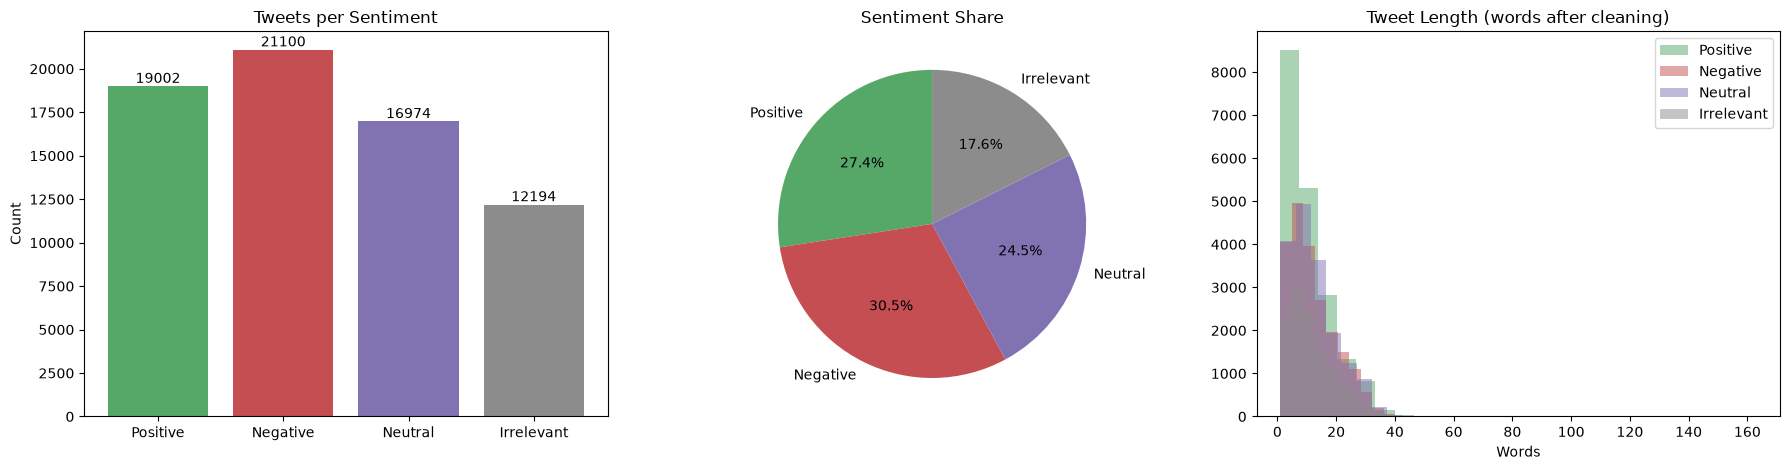

Saved: e:\Practice\Final Project\Credit-Score-pipeline\wordclouds\sentiment_distribution.png

Tweet length by sentiment (words / characters):
            n_words  n_chars
Sentiment                   
Positive      10.45   101.09
Negative      11.80   115.78
Neutral       12.50   123.03
Irrelevant    11.51   114.01


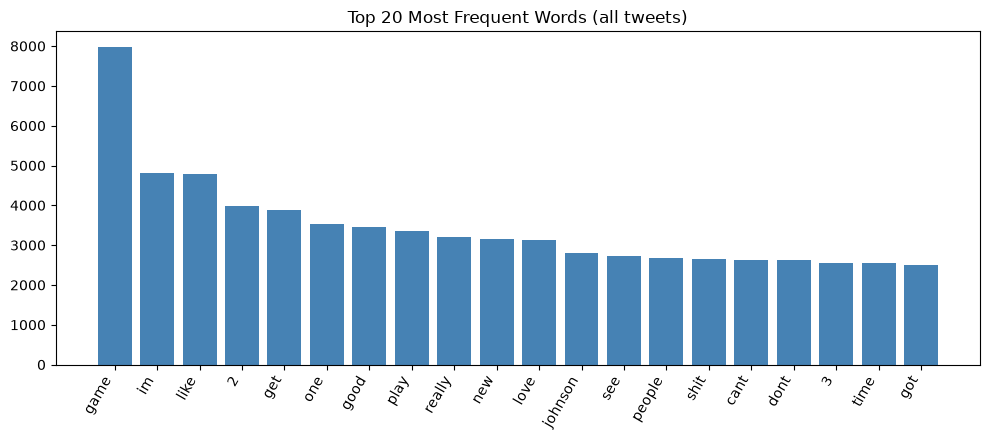

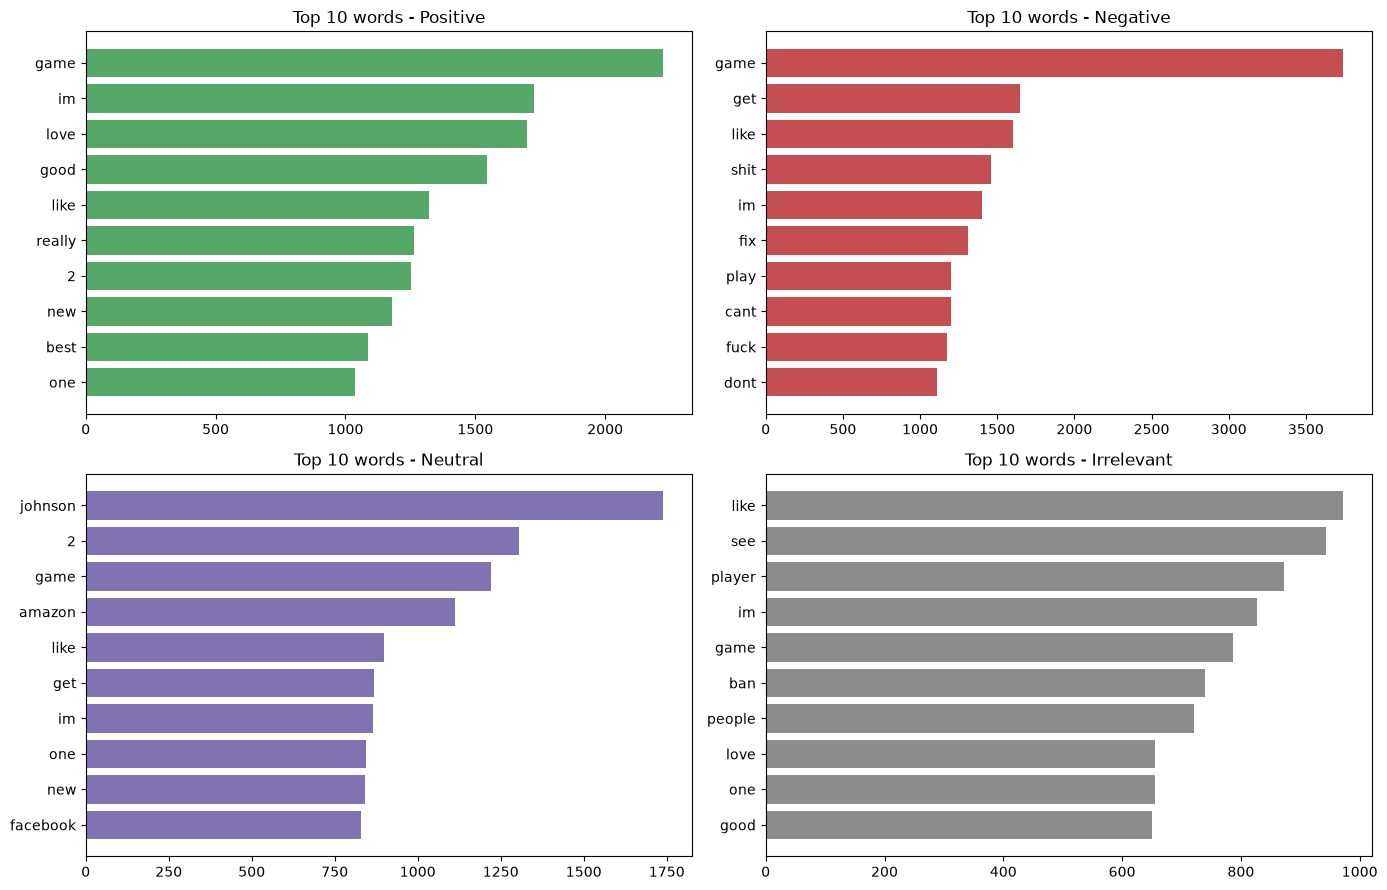

In [8]:

import os
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

IMG_DIR = 'wordclouds'          
os.makedirs(IMG_DIR, exist_ok=True)
SENT_COLORS = {'Positive': '#55A868', 'Negative': '#C44E52', 'Neutral': '#8172B2', 'Irrelevant': '#8C8C8C'}

counts = df['Sentiment'].value_counts().reindex(VALID_LABELS)
print("Class distribution:")
print(pd.DataFrame({'Count': counts, 'Percent': (counts / counts.sum() * 100).round(2)}))

df['n_words'] = df['Cleaned_Text'].str.split().str.len()
df['n_chars'] = df['Text'].astype(str).str.len()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].bar(counts.index, counts.values, color=[SENT_COLORS[l] for l in counts.index])
axes[0].set_title('Tweets per Sentiment')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v, str(v), ha='center', va='bottom')
axes[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%',
            colors=[SENT_COLORS[l] for l in counts.index], startangle=90)
axes[1].set_title('Sentiment Share')
for l in VALID_LABELS:
    axes[2].hist(df.loc[df['Sentiment'] == l, 'n_words'], bins=25, alpha=0.5, label=l, color=SENT_COLORS[l])
axes[2].set_title('Tweet Length (words after cleaning)')
axes[2].set_xlabel('Words')
axes[2].legend()
plt.tight_layout()
fig.savefig(os.path.join(IMG_DIR, 'sentiment_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {os.path.abspath(os.path.join(IMG_DIR, 'sentiment_distribution.png'))}")

print("\nTweet length by sentiment (words / characters):")
print(df.groupby('Sentiment')[['n_words', 'n_chars']].mean().round(2).reindex(VALID_LABELS))


all_freq = Counter(w for t in df['Cleaned_Text'] for w in t.split())
top_all = pd.DataFrame(all_freq.most_common(20), columns=['Word', 'Frequency'])
plt.figure(figsize=(10, 4.5))
plt.bar(top_all['Word'], top_all['Frequency'], color='steelblue')
plt.xticks(rotation=60, ha='right')
plt.title('Top 20 Most Frequent Words (all tweets)')
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, l in zip(axes.ravel(), VALID_LABELS):
    freq = Counter(w for t in df.loc[df['Sentiment'] == l, 'Cleaned_Text'] for w in t.split()).most_common(10)
    words, vals = zip(*freq)
    ax.barh(words[::-1], vals[::-1], color=SENT_COLORS[l])
    ax.set_title(f'Top 10 words - {l}')
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer


tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.9) 


X_features = tfidf.fit_transform(df['Cleaned_Text'])


y_labels = df['Sentiment'].values


print("Vectorization Pipeline Complete")
print(f"Total processed rows (Samples): {X_features.shape[0]}")
print(f"Total structural features (Vocabulary Columns): {X_features.shape[1]}")
print(f"Feature Array DataType: {X_features.dtype}")


print("\nFirst row numerical vector representation (Non-zero positions):")
print(X_features[0])

Vectorization Pipeline Complete
Total processed rows (Samples): 69270
Total structural features (Vocabulary Columns): 5000
Feature Array DataType: float64

First row numerical vector representation (Non-zero positions):
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5 stored elements and shape (1, 5000)>
  Coords	Values
  (0, 2272)	0.2776190155961191
  (0, 1900)	0.37097001847278555
  (0, 582)	0.359630297777981
  (0, 2947)	0.5826955376521408
  (0, 2280)	0.5625307875078005


In [10]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from scipy import sparse          

X_features = sparse.csr_matrix(X_features)
y_labels = np.asarray(y_labels)
if X_features.shape[0] != len(y_labels):
    raise ValueError(f"Row mismatch: {X_features.shape[0]} feature rows vs {len(y_labels)} labels. "
                     f"Re-run the cells above in order (Run All).")
train_idx, test_idx = train_test_split(np.arange(len(y_labels)), test_size=0.2,
                                       random_state=42, stratify=y_labels)
X_train, X_test = X_features[train_idx], X_features[test_idx]
y_train, y_test = y_labels[train_idx], y_labels[test_idx]

print(f"Training Set Rows: {X_train.shape[0]}")
print(f"Testing Set Rows: {X_test.shape[0]}\n")


models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear Support Vector Machine": LinearSVC(random_state=42)
}

best_accuracy = 0
best_model_name = ""
trained_models = {}

for name, model in models.items():
    print(f"Training {name}")
    model.fit(X_train, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{name} Score: {acc:.4f}\n")

    if acc > best_accuracy:
        best_accuracy = acc
        best_model_name = name


print(f" CHAMPION PIPELINE VARIATION: {best_model_name}")
champion_predictions = trained_models[best_model_name].predict(X_test)
print(classification_report(y_test, champion_predictions))

print("\n Confusion Matrix Grid")
cm = confusion_matrix(y_test, champion_predictions, labels=VALID_LABELS)
cm_df = pd.DataFrame(cm, index=[f"Actual_{l}" for l in VALID_LABELS], columns=[f"Predicted_{l}" for l in VALID_LABELS])
print(cm_df)

Training Set Rows: 55416
Testing Set Rows: 13854

Training Naive Bayes
Naive Bayes Score: 0.6356

Training Logistic Regression
Logistic Regression Score: 0.6863

Training Linear Support Vector Machine
Linear Support Vector Machine Score: 0.7015

 CHAMPION PIPELINE VARIATION: Linear Support Vector Machine
              precision    recall  f1-score   support

  Irrelevant       0.68      0.59      0.63      2439
    Negative       0.74      0.78      0.76      4220
     Neutral       0.66      0.65      0.65      3395
    Positive       0.70      0.73      0.72      3800

    accuracy                           0.70     13854
   macro avg       0.70      0.69      0.69     13854
weighted avg       0.70      0.70      0.70     13854


 Confusion Matrix Grid
                   Predicted_Positive  Predicted_Negative  Predicted_Neutral  \
Actual_Positive                  2772                 367                424   
Actual_Negative                   309                3312                41

             PROJECT SENTIMENT PULSE: EVALUATION DASHBOARD        
CHAMPION ARCHITECTURE:  Linear Support Vector Machine
FINAL PIPELINE ACCURACY: 70.15%
UNIVERSAL MACRO F1-SCORE AVERAGE: 0.6906
CLASS-BY-CLASS METRIC ANALYSIS:

SENTIMENT CLASS: **POSITIVE**
  · PRECISION (Exactness of Guesses):  70.16%
  · RECALL (Coverage of True Values):  72.95%
  · F1-SCORE (Balanced Performance):   0.7153
  · Sample Support Size (Test Pool):   3800 rows

SENTIMENT CLASS: **NEGATIVE**
  · PRECISION (Exactness of Guesses):  74.31%
  · RECALL (Coverage of True Values):  78.48%
  · F1-SCORE (Balanced Performance):   0.7634
  · Sample Support Size (Test Pool):   4220 rows

SENTIMENT CLASS: **NEUTRAL**
  · PRECISION (Exactness of Guesses):  65.96%
  · RECALL (Coverage of True Values):  64.89%
  · F1-SCORE (Balanced Performance):   0.6542
  · Sample Support Size (Test Pool):   3395 rows

SENTIMENT CLASS: **IRRELEVANT**
  · PRECISION (Exactness of Guesses):  67.95%
  · RECALL (Coverage of True Values):  58.

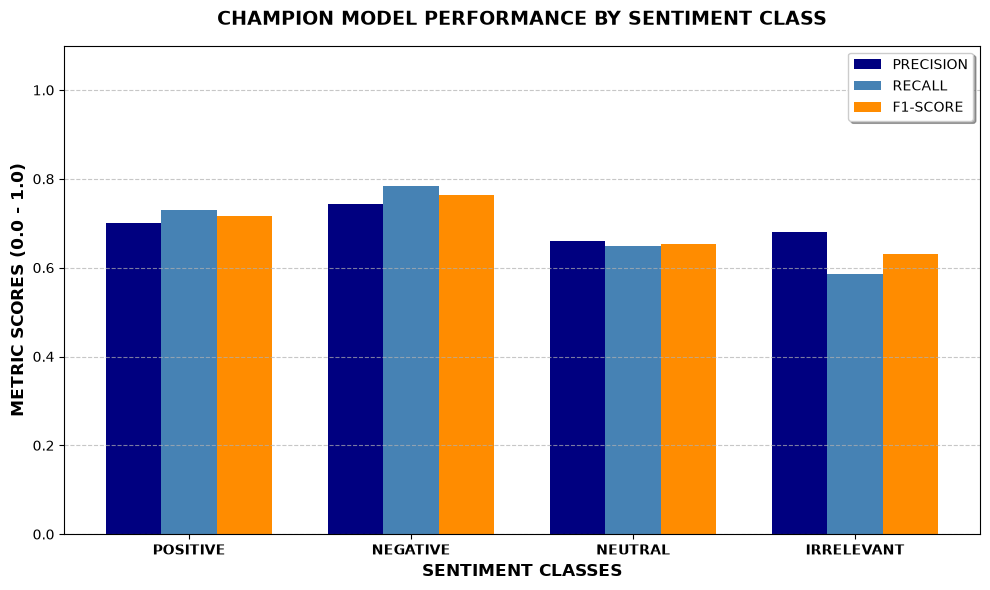

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix


y_pred = trained_models[best_model_name].predict(X_test)
valid_labels = ['Positive', 'Negative', 'Neutral', 'Irrelevant']


accuracy = accuracy_score(y_test, y_pred)


precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=valid_labels, average=None
)


macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average='macro'
)


print("             PROJECT SENTIMENT PULSE: EVALUATION DASHBOARD        ")

print(f"CHAMPION ARCHITECTURE:  {best_model_name}")
print(f"FINAL PIPELINE ACCURACY: {accuracy * 100:.2f}%")
print(f"UNIVERSAL MACRO F1-SCORE AVERAGE: {macro_f1:.4f}")

print("CLASS-BY-CLASS METRIC ANALYSIS:")
metrics_summary = []
for i, label in enumerate(valid_labels):
    print(f"\nSENTIMENT CLASS: **{label.upper()}**")
    print(f"  · PRECISION (Exactness of Guesses):  {precision[i]*100:.2f}%")
    print(f"  · RECALL (Coverage of True Values):  {recall[i]*100:.2f}%")
    print(f"  · F1-SCORE (Balanced Performance):   {f1[i]:.4f}")
    print(f"  · Sample Support Size (Test Pool):   {support[i]} rows")

    metrics_summary.append({
        "Sentiment Class": label,
        "Precision": f"{precision[i]*100:.2f}%",
        "Recall": f"{recall[i]*100:.2f}%",
        "F1-Score": round(f1[i], 4)
    })

print("CONFUSION MATRIX GRID DEEP-DIVE ANALYSIS:")
cm = confusion_matrix(y_test, y_pred, labels=valid_labels)
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{l}" for l in valid_labels],
    columns=[f"Predicted_{l}" for l in valid_labels]
)
print(cm_df)

print("\nEVALUATION INSIGHTS FOR PROJECT REPORT:")
print(f"1. ERROR ANALYSIS: The model's strongest performance is in the '{valid_labels[np.argmax(f1)]}' class with an F1 of {max(f1):.2f}.")
print(f"2. BASELINE COMPARISON: Random guessing on 4 classes yields 25.00% accuracy.")
print(f"   Our pipeline outperforms the random baseline by {((accuracy - 0.25) * 100):.2f}% absolute percentage points.")



print("\nGENERATING VISUAL PERFORMANCE CHART...")


x_indexes = np.arange(len(valid_labels))
bar_width = 0.25

plt.figure(figsize=(10, 6))


plt.bar(x_indexes - bar_width, precision, width=bar_width, label='PRECISION', color='navy')
plt.bar(x_indexes, recall, width=bar_width, label='RECALL', color='steelblue')
plt.bar(x_indexes + bar_width, f1, width=bar_width, label='F1-SCORE', color='darkorange')


plt.title('CHAMPION MODEL PERFORMANCE BY SENTIMENT CLASS', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('SENTIMENT CLASSES', fontsize=12, fontweight='bold')
plt.ylabel('METRIC SCORES (0.0 - 1.0)', fontsize=12, fontweight='bold')
plt.xticks(ticks=x_indexes, labels=[l.upper() for l in valid_labels], fontsize=10, fontweight='bold')
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='upper right', fontsize=10, shadow=True)

plt.tight_layout()
plt.show()

Naive Bayes                      CV weighted-F1: 0.6238 +/- 0.0012
Logistic Regression              CV weighted-F1: 0.6817 +/- 0.0046
Linear Support Vector Machine    CV weighted-F1: 0.6996 +/- 0.0026


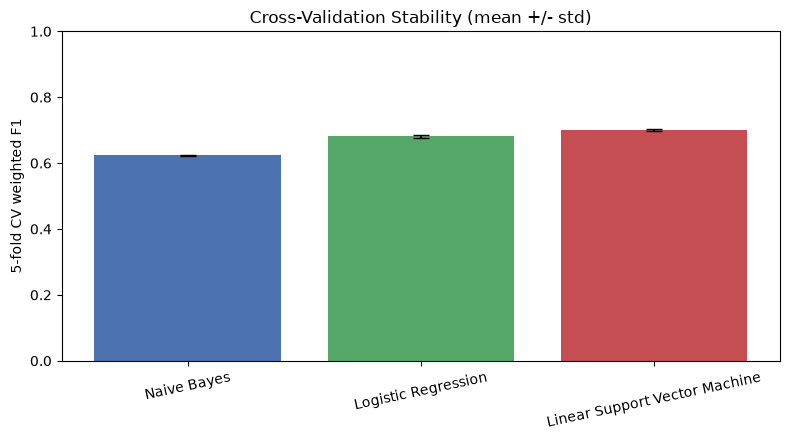

In [13]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(clone(model), X_train, y_train, cv=skf, scoring='f1_weighted', n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:32s} CV weighted-F1: {scores.mean():.4f} +/- {scores.std():.4f}")

plt.figure(figsize=(8, 4.5))
plt.bar(list(cv_results), [s.mean() for s in cv_results.values()],
        yerr=[s.std() for s in cv_results.values()], capsize=6, color=['#4C72B0', '#55A868', '#C44E52'])
plt.ylim(0, 1)
plt.ylabel('5-fold CV weighted F1')
plt.title('Cross-Validation Stability (mean +/- std)')
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()

Training class counts:
 Negative      16880
Positive      15202
Neutral       13579
Irrelevant     9755
Imbalance ratio (largest/smallest): 1.73  ->  imbalanced (ratio > 1.5)
SMOTE: 55416 -> 67520 training rows
RandomOverSampling: 55416 -> 67520 training rows

Performance before (Original) vs after balancing:


,Model,Balancing,Accuracy,Precision,Recall,F1-Score,Macro F1
0,Naive Bayes,Original,0.6356,0.6418,0.6356,0.6239,0.6068
1,Logistic Regression,Original,0.6863,0.6843,0.6863,0.6836,0.6721
2,Linear Support Vector Machine,Original,0.7015,0.7000,0.7015,0.6999,0.6906
3,Naive Bayes,SMOTE,0.6387,0.6415,0.6387,0.6386,0.6275
4,Logistic Regression,SMOTE,0.6823,0.6867,0.6823,0.6835,0.6738
5,Linear Support Vector Machine,SMOTE,0.6976,0.7014,0.6976,0.6986,0.6901
6,Naive Bayes,RandomOverSampling,0.6394,0.6425,0.6394,0.6393,0.6285
7,Logistic Regression,RandomOverSampling,0.6858,0.6909,0.6858,0.6872,0.6780
8,Linear Support Vector Machine,RandomOverSampling,0.6985,0.7022,0.6985,0.6994,0.6916


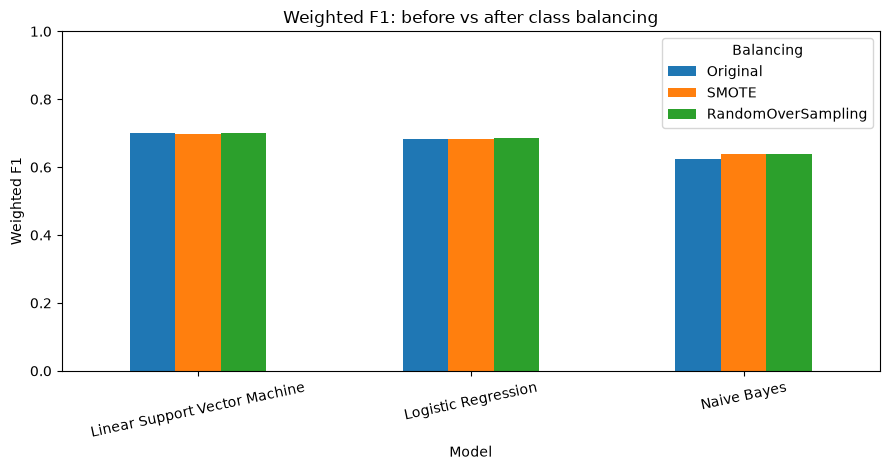

In [14]:
import sys, subprocess
from sklearn.metrics import precision_score, recall_score, f1_score

train_counts = pd.Series(y_train).value_counts()
ratio = train_counts.max() / train_counts.min()
print("Training class counts:\n", train_counts.to_string())
print(f"Imbalance ratio (largest/smallest): {ratio:.2f}  ->  "
      f"{'imbalanced (ratio > 1.5)' if ratio > 1.5 else 'fairly balanced'}")


try:
    from imblearn.over_sampling import SMOTE, RandomOverSampler
except ImportError:
    print("Installing imbalanced-learn ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
    from imblearn.over_sampling import SMOTE, RandomOverSampler

samplers = {'SMOTE': SMOTE(random_state=42), 'RandomOverSampling': RandomOverSampler(random_state=42)}
resampled = {'Original': (X_train, y_train)}
for sname, sampler in samplers.items():
    resampled[sname] = sampler.fit_resample(X_train, y_train)
    print(f"{sname}: {X_train.shape[0]} -> {resampled[sname][0].shape[0]} training rows")

rows, balanced_models = [], {}
for strategy, (Xr, yr) in resampled.items():
    for name, base in models.items():
        m = clone(base).fit(Xr, yr)
        pred = m.predict(X_test)
        rows.append({'Model': name, 'Balancing': strategy,
                     'Accuracy': accuracy_score(y_test, pred),
                     'Precision': precision_score(y_test, pred, average='weighted', zero_division=0),
                     'Recall': recall_score(y_test, pred, average='weighted', zero_division=0),
                     'F1-Score': f1_score(y_test, pred, average='weighted', zero_division=0),
                     'Macro F1': f1_score(y_test, pred, average='macro', zero_division=0)})
        balanced_models[(name, strategy)] = m

comparison = pd.DataFrame(rows)
print("\nPerformance before (Original) vs after balancing:")
display(comparison.round(4))

pivot = comparison.pivot(index='Model', columns='Balancing', values='F1-Score')[list(resampled)]
pivot.plot(kind='bar', figsize=(9, 4.8), rot=12, ylim=(0, 1))
plt.ylabel('Weighted F1')
plt.title('Weighted F1: before vs after class balancing')
plt.tight_layout()
plt.show()

Leaderboard (sorted by weighted F1):


,Model,Balancing,Accuracy,Precision,Recall,F1-Score,Macro F1
0,Linear Support Vector Machine,Original,0.7015,0.7000,0.7015,0.6999,0.6906
1,Linear Support Vector Machine,RandomOverSampling,0.6985,0.7022,0.6985,0.6994,0.6916
2,Linear Support Vector Machine,SMOTE,0.6976,0.7014,0.6976,0.6986,0.6901
3,Logistic Regression,RandomOverSampling,0.6858,0.6909,0.6858,0.6872,0.6780
4,Logistic Regression,Original,0.6863,0.6843,0.6863,0.6836,0.6721
5,Logistic Regression,SMOTE,0.6823,0.6867,0.6823,0.6835,0.6738
6,Naive Bayes,RandomOverSampling,0.6394,0.6425,0.6394,0.6393,0.6285
7,Naive Bayes,SMOTE,0.6387,0.6415,0.6387,0.6386,0.6275
8,Naive Bayes,Original,0.6356,0.6418,0.6356,0.6239,0.6068



BEST MODEL (by weighted F1): Linear Support Vector Machine [Original]  |  F1 = 0.6999  |  Accuracy = 0.7015

Classification report:
              precision    recall  f1-score   support

    Positive       0.70      0.73      0.72      3800
    Negative       0.74      0.78      0.76      4220
     Neutral       0.66      0.65      0.65      3395
  Irrelevant       0.68      0.59      0.63      2439

    accuracy                           0.70     13854
   macro avg       0.70      0.69      0.69     13854
weighted avg       0.70      0.70      0.70     13854



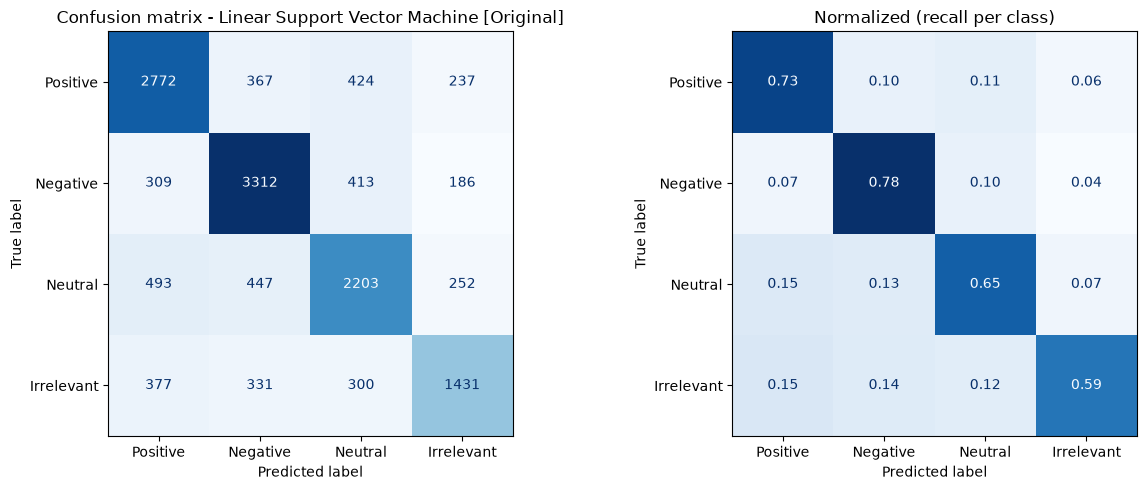

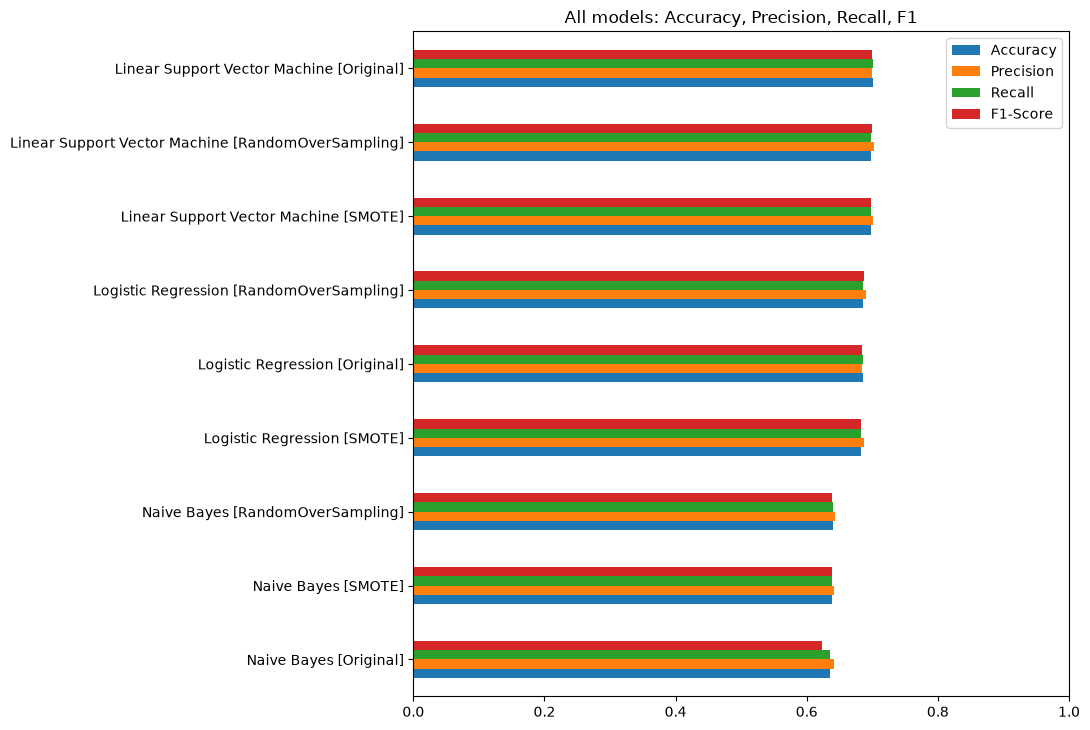

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

print("Leaderboard (sorted by weighted F1):")
leaderboard = comparison.sort_values('F1-Score', ascending=False).reset_index(drop=True)
display(leaderboard.round(4))


best_row = leaderboard.iloc[0]
best_model_name = f"{best_row['Model']} [{best_row['Balancing']}]"      
best_model = balanced_models[(best_row['Model'], best_row['Balancing'])]
best_pred = best_model.predict(X_test)
print(f"\nBEST MODEL (by weighted F1): {best_model_name}  |  F1 = {best_row['F1-Score']:.4f}  |  "
      f"Accuracy = {best_row['Accuracy']:.4f}")

print("\nClassification report:")
print(classification_report(y_test, best_pred, labels=VALID_LABELS, zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, labels=VALID_LABELS, cmap='Blues',
                                        ax=axes[0], colorbar=False)
axes[0].set_title(f'Confusion matrix - {best_model_name}')
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, labels=VALID_LABELS, normalize='true',
                                        values_format='.2f', cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title('Normalized (recall per class)')
plt.tight_layout()
plt.show()


metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
plot_df = leaderboard.set_index(leaderboard['Model'] + ' [' + leaderboard['Balancing'] + ']')[metric_cols]
plot_df.sort_values('F1-Score').plot(kind='barh', figsize=(11, 0.6 * len(plot_df) + 2), xlim=(0, 1))
plt.title('All models: Accuracy, Precision, Recall, F1')
plt.tight_layout()
plt.show()

Saved: e:\Practice\Final Project\Credit-Score-pipeline\wordclouds\wordcloud_positive.png
Saved: e:\Practice\Final Project\Credit-Score-pipeline\wordclouds\wordcloud_negative.png
Saved: e:\Practice\Final Project\Credit-Score-pipeline\wordclouds\wordcloud_neutral.png


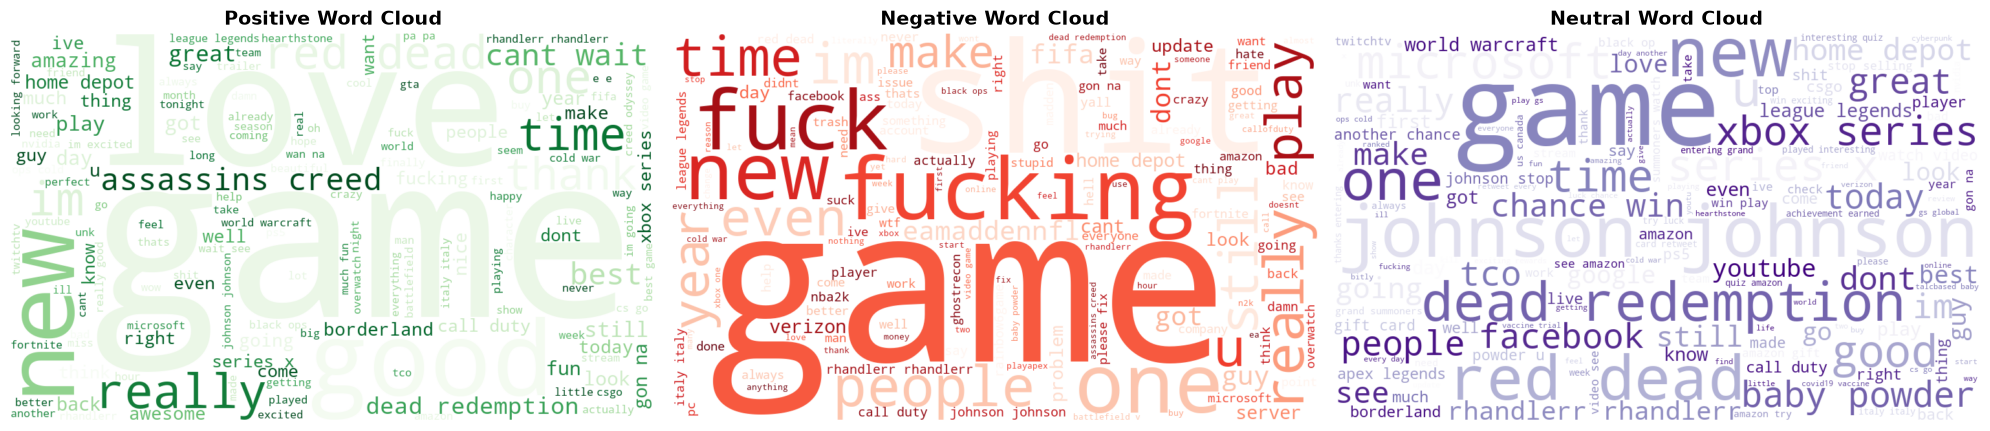

In [16]:
import sys, subprocess
try:
    from wordcloud import WordCloud
except ImportError:
    print("Installing wordcloud ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wordcloud"])
    from wordcloud import WordCloud

CLOUD_COLORMAPS = {'Positive': 'Greens', 'Negative': 'Reds', 'Neutral': 'Purples'}
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (sentiment, cmap) in zip(axes, CLOUD_COLORMAPS.items()):
    text = " ".join(df.loc[df['Sentiment'] == sentiment, 'Cleaned_Text'])
    if not text.strip():
        print(f"[WARNING] No text found for '{sentiment}' - skipping its word cloud.")
        ax.axis('off')
        continue
    wc = WordCloud(width=1000, height=600, background_color='white', colormap=cmap,
                   max_words=150, random_state=42).generate(text)
    path = os.path.join(IMG_DIR, f'wordcloud_{sentiment.lower()}.png')
    try:
        wc.to_file(path)
        print(f"Saved: {os.path.abspath(path)}")
    except OSError as e:
        print(f"[ERROR] Could not save {path}: {e}")
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(f'{sentiment} Word Cloud', fontsize=14, fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [18]:
import pickle
from pathlib import Path

SAVE_DIR = Path('.').resolve()          

def save_pkl(obj, filename):

    if not filename.endswith('.pkl'):
        raise ValueError(f"Filename must end with .pkl (got '{filename}')")
    try:
        SAVE_DIR.mkdir(parents=True, exist_ok=True)
        path = SAVE_DIR / filename
        with open(path, 'wb') as f:
            pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
    except (OSError, pickle.PicklingError) as e:
        raise RuntimeError(f"Could not save '{filename}' to '{SAVE_DIR}': {e}") from e
    return path

try:
    for var in ('best_model', 'tfidf'):
        if var not in globals():
            raise NameError(f"'{var}' is not defined - run all cells above first (Run All).")
    model_path = save_pkl(best_model, 'best_model.pkl')             
    vec_path = save_pkl(tfidf, 'tfidf_vectorizer.pkl')               
    
    print("FILES SAVED SUCCESSFULLY")
    for p in (model_path, vec_path):
        print(f"  File name : {p.name}\n  Location  : {p.parent}\n  Full path : {p}\n"
              f"  Size      : {p.stat().st_size / 1024:.1f} KB\n  ")
    print(f"  Saved model: {best_model_name}")
    
except Exception as err:
    print(f"[ERROR] Saving failed: {err}", file=sys.stderr)
    raise


try:
    with open(model_path, 'rb') as f:
        loaded_model = pickle.load(f)
    with open(vec_path, 'rb') as f:
        loaded_tfidf = pickle.load(f)
except Exception as err:
    raise RuntimeError(f"Saved files could not be loaded back: {err}") from err
check = (loaded_model.predict(loaded_tfidf.transform(df['Cleaned_Text'].head(200)))
         == best_model.predict(tfidf.transform(df['Cleaned_Text'].head(200)))).all()

try:
    from google.colab import files
    files.download(str(model_path)); files.download(str(vec_path))
except ImportError:
    pass

print(f"Verification: model + vectorizer load OK, predictions identical to in-memory model -> {check}")
assert check, "Loaded model gives different predictions than the original!"


def predict_sentiment(texts):
    if isinstance(texts, str):
        texts = [texts]
    cleaned = [clean_text(t) for t in texts]
    X_new = loaded_tfidf.transform(cleaned)
    labels = loaded_model.predict(X_new)
    if hasattr(loaded_model, 'predict_proba'):
        conf = loaded_model.predict_proba(X_new).max(axis=1)
    else:                                      
        conf = loaded_model.decision_function(X_new).max(axis=1)
    return pd.DataFrame({'Text': texts, 'Predicted': labels, 'Score': np.round(conf, 3)})

new_samples = [
    "I absolutely love this game, it is amazing!",
    "This update is terrible and the servers keep crashing",
    "Just downloaded the new patch",
    "Not happy with the new controller at all",
    "Check out my cooking video https://example.com/pasta",
]
predict_sentiment(new_samples)

FILES SAVED SUCCESSFULLY
  File name : best_model.pkl
  Location  : E:\Practice\Final Project\Credit-Score-pipeline
  Full path : E:\Practice\Final Project\Credit-Score-pipeline\best_model.pkl
  Size      : 156.9 KB
  
  File name : tfidf_vectorizer.pkl
  Location  : E:\Practice\Final Project\Credit-Score-pipeline
  Full path : E:\Practice\Final Project\Credit-Score-pipeline\tfidf_vectorizer.pkl
  Size      : 181.6 KB
  
  Saved model: Linear Support Vector Machine [Original]
Verification: model + vectorizer load OK, predictions identical to in-memory model -> True


,Text,Predicted,Score
0,"I absolutely love this game, it is amazing!",Positive,1.107
1,This update is terrible and the servers keep c...,Negative,1.804
2,Just downloaded the new patch,Positive,0.281
3,Not happy with the new controller at all,Positive,-0.194
4,Check out my cooking video https://example.com...,Neutral,0.668


# Flask API for Postman
The cells below write `app.py` (a Flask API that loads `best_model.pkl` and `tfidf_vectorizer.pkl`), start it, and show how to call it from Postman.

| Method | URL | Body (Postman: Body -> raw -> JSON) |
|---|---|---|
| GET | `http://127.0.0.1:5000/health` | none |
| POST | `http://127.0.0.1:5000/predict` | `{"text": "I love this game"}` |
| POST | `http://127.0.0.1:5000/predict/batch` | `{"texts": ["I love it", "worst update ever"]}` |

Postman and the server must run on the same computer (local Jupyter). On Google Colab, download `app.py` and the two `.pkl` files and run `python app.py` on your own machine instead.

In [19]:
APP_CODE = '"""Flask API for the Twitter sentiment model - test it with Postman.\n\nRun:   python app.py          (needs best_model.pkl + tfidf_vectorizer.pkl in this same folder)\nEnv:   HOST (default 0.0.0.0)  PORT (default 5000)\n"""\nimport os\nimport pickle\nimport re\nimport sys\nfrom pathlib import Path\n\nimport nltk\nimport numpy as np\nfrom flask import Flask, jsonify, request\nfrom nltk.corpus import stopwords\nfrom nltk.tokenize import word_tokenize\n\nBASE_DIR = Path(__file__).resolve().parent\nMODEL_PATH = BASE_DIR / "best_model.pkl"\nVECTORIZER_PATH = BASE_DIR / "tfidf_vectorizer.pkl"\nMAX_BATCH = 500\n\n\ndef ensure_nltk():\n    """Make sure the NLTK data used by the notebook\'s clean_text() is available."""\n    for resource, path in (("punkt_tab", "tokenizers/punkt_tab"), ("stopwords", "corpora/stopwords")):\n        try:\n            nltk.data.find(path)\n        except LookupError:\n            print(f"Downloading NLTK resource \'{resource}\' ...")\n            nltk.download(resource, quiet=True)\n\n\ndef load_pickle(path):\n    if not path.exists():\n        raise FileNotFoundError(\n            f"\'{path.name}\' not found in {path.parent}. Run the notebook\'s save-model cell first "\n            f"and keep the .pkl files in the same folder as app.py.")\n    try:\n        with open(path, "rb") as f:\n            return pickle.load(f)\n    except Exception as e:\n        raise RuntimeError(f"Could not load \'{path.name}\': {e}. Use the same scikit-learn version "\n                           f"that created it.") from e\n\n\nensure_nltk()\nSTOP_WORDS = set(stopwords.words("english"))\n\ntry:\n    model = load_pickle(MODEL_PATH)\n    vectorizer = load_pickle(VECTORIZER_PATH)\nexcept Exception as err:\n    print(f"[STARTUP ERROR] {err}", file=sys.stderr)\n    sys.exit(1)\n\n\ndef clean_text(text):\n    """Same cleaning as the notebook (lowercase, drop <unk>, URLs, symbols, stopwords)."""\n    text = str(text).lower()\n    text = text.replace("<unk>", "")\n    text = re.sub(r"http\\S+|www\\S+|pic\\.twitter\\S+", "", text)\n    text = re.sub(r"[^a-zA-Z0-9\\s]", "", text)\n    words = word_tokenize(text)\n    return " ".join(w for w in words if w not in STOP_WORDS)\n\n\ndef predict_texts(texts):\n    cleaned = [clean_text(t) for t in texts]\n    X = vectorizer.transform(cleaned)\n    labels = model.predict(X)\n    if hasattr(model, "predict_proba"):\n        probs, kind = model.predict_proba(X), "probability"\n    else:  # LinearSVC has no predict_proba -> softmax over decision scores\n        d = model.decision_function(X)\n        e = np.exp(d - d.max(axis=1, keepdims=True))\n        probs, kind = e / e.sum(axis=1, keepdims=True), "softmax of SVM decision scores (not a calibrated probability)"\n    results = []\n    for text, clean, label, p in zip(texts, cleaned, labels, probs):\n        item = {\n            "text": text,\n            "cleaned_text": clean,\n            "sentiment": str(label),\n            "confidence": round(float(p.max()), 4),\n            "scores": {str(c): round(float(v), 4) for c, v in zip(model.classes_, p)},\n        }\n        if not clean.strip():\n            item["warning"] = "Nothing left after cleaning (only URLs/symbols/stopwords) - prediction is unreliable."\n        results.append(item)\n    return results, kind\n\n\napp = Flask(__name__)\n\n\ndef error(message, status=400):\n    return jsonify({"error": message}), status\n\n\n@app.get("/")\ndef index():\n    return jsonify({\n        "service": "Twitter Sentiment API (Flask)",\n        "endpoints": {\n            "GET /health": "service + model status",\n            "POST /predict": \'body: {"text": "your tweet"}\',\n            "POST /predict/batch": \'body: {"texts": ["tweet 1", "tweet 2"]}\',\n        },\n    })\n\n\n@app.get("/health")\ndef health():\n    return jsonify({"status": "ok", "model": type(model).__name__,\n                    "classes": [str(c) for c in model.classes_],\n                    "vocabulary_size": len(vectorizer.vocabulary_)})\n\n\n@app.post("/predict")\ndef predict():\n    data = request.get_json(silent=True)\n    if not isinstance(data, dict):\n        data = request.form.to_dict() or request.args.to_dict()      # form-data / x-www-form-urlencoded / ?text=\n    text = data.get("text")\n    if not isinstance(text, str) or not text.strip():\n        return error(\'Send a non-empty "text" field, e.g. {"text": "I love this game"} \'\n                     \'(Postman: Body -> raw -> JSON).\')\n    results, kind = predict_texts([text])\n    return jsonify({**results[0], "confidence_type": kind})\n\n\n@app.post("/predict/batch")\ndef predict_batch():\n    data = request.get_json(silent=True)\n    if isinstance(data, dict):\n        texts = data.get("texts")\n    else:\n        texts = request.form.getlist("texts") or None                # form-data: repeat the key "texts"\n    if not isinstance(texts, list) or not texts:\n        return error(\'Send a non-empty "texts" list, e.g. {"texts": ["I love it", "worst update ever"]}.\')\n    if len(texts) > MAX_BATCH:\n        return error(f"Too many texts ({len(texts)}). Maximum per request is {MAX_BATCH}.", 413)\n    if not all(isinstance(t, str) and t.strip() for t in texts):\n        return error(\'Every item in "texts" must be a non-empty string.\')\n    results, kind = predict_texts(texts)\n    return jsonify({"count": len(results), "confidence_type": kind, "predictions": results})\n\n\n@app.errorhandler(404)\ndef not_found(_):\n    return error("Route not found. Try GET /, GET /health, POST /predict or POST /predict/batch.", 404)\n\n\n@app.errorhandler(405)\ndef bad_method(_):\n    return error("Method not allowed for this route (prediction routes need POST).", 405)\n\n\n@app.errorhandler(500)\ndef server_error(_):\n    return error("Internal server error - check the terminal / flask_server.log for details.", 500)\n\n\nif __name__ == "__main__":\n    host = os.environ.get("HOST", "0.0.0.0")\n    port = int(os.environ.get("PORT", 5000))\n    print(f"Model: {type(model).__name__} | classes: {list(model.classes_)}")\n    print(f"Open in Postman: http://127.0.0.1:{port}/health")\n    app.run(host=host, port=port, debug=False)\n'

import sys, subprocess
try:
    import flask
except ImportError:
    print("Installing flask ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "flask"])

try:
    for needed in ("best_model.pkl", "tfidf_vectorizer.pkl"):
        if not (SAVE_DIR / needed).exists():
            raise FileNotFoundError(f"{needed} not found in {SAVE_DIR}. Run the save-model cell above first.")
    app_path = SAVE_DIR / "app.py"
    app_path.write_text(APP_CODE, encoding="utf-8")
except Exception as err:
    print(f"[ERROR] Could not create app.py: {err}", file=sys.stderr)
    raise


print("FLASK APP FILE CREATED")
print(f"  File name : {app_path.name}")
print(f"  Location  : {app_path.parent}")
print(f"  Full path : {app_path}")
print(f"  Run later : python app.py")



FLASK APP FILE CREATED
  File name : app.py
  Location  : E:\Practice\Final Project\Credit-Score-pipeline
  Full path : E:\Practice\Final Project\Credit-Score-pipeline\app.py
  Run later : python app.py


In [20]:
import os, socket, time, urllib.request, urllib.error

PORT = 5000
URL = f"http://127.0.0.1:{PORT}"

with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
    if s.connect_ex(("127.0.0.1", PORT)) == 0:
        raise RuntimeError(f"Port {PORT} is already in use. Stop the other program, or change PORT here "
                           f"(on macOS, turn off AirPlay Receiver or use e.g. PORT = 5001).")

log_path = SAVE_DIR / "flask_server.log"
log_file = open(log_path, "w")
flask_proc = subprocess.Popen([sys.executable, str(app_path)], cwd=str(SAVE_DIR),
                              stdout=log_file, stderr=subprocess.STDOUT,
                              env={**os.environ, "PORT": str(PORT)})

started = False
for _ in range(30):
    if flask_proc.poll() is not None:
        break
    try:
        urllib.request.urlopen(URL + "/health", timeout=1)
        started = True
        break
    except (urllib.error.URLError, ConnectionError, OSError):
        time.sleep(1)

if started:
    print("FLASK SERVER RUNNING")
    print(f"  Health check : GET  {URL}/health")
    print(f"  Predict      : POST {URL}/predict        body: {{\"text\": \"I love this game\"}}")
    print(f"  Batch        : POST {URL}/predict/batch  body: {{\"texts\": [\"I love it\", \"worst update ever\"]}}")
    print(f"  Server log   : {log_path}")
    print("  Stop it with : flask_proc.terminate()")
else:
    log_file.flush()
    print("[ERROR] Server did not start. Last log lines:\n" + "".join(open(log_path).readlines()[-15:]), file=sys.stderr)


FLASK SERVER RUNNING
  Health check : GET  http://127.0.0.1:5000/health
  Predict      : POST http://127.0.0.1:5000/predict        body: {"text": "I love this game"}
  Batch        : POST http://127.0.0.1:5000/predict/batch  body: {"texts": ["I love it", "worst update ever"]}
  Server log   : E:\Practice\Final Project\Credit-Score-pipeline\flask_server.log
  Stop it with : flask_proc.terminate()


In [21]:
import json
def call(method, path, body=None):
    req = urllib.request.Request(URL + path, method=method,
                                 data=json.dumps(body).encode() if body is not None else None,
                                 headers={"Content-Type": "application/json"})
    try:
        with urllib.request.urlopen(req, timeout=10) as r:
            return json.load(r)
    except urllib.error.HTTPError as e:
        return json.load(e)

print(json.dumps(call("GET", "/health"), indent=2))
print(json.dumps(call("POST", "/predict", {"text": "I absolutely love this game, it is amazing!"}), indent=2))
print(json.dumps(call("POST", "/predict", {"text": ""}), indent=2))


{
  "classes": [
    "Irrelevant",
    "Negative",
    "Neutral",
    "Positive"
  ],
  "model": "LinearSVC",
  "status": "ok",
  "vocabulary_size": 5000
}
{
  "cleaned_text": "absolutely love game amazing",
  "confidence": 0.7426,
  "confidence_type": "softmax of SVM decision scores (not a calibrated probability)",
  "scores": {
    "Irrelevant": 0.0609,
    "Negative": 0.0163,
    "Neutral": 0.1802,
    "Positive": 0.7426
  },
  "sentiment": "Positive",
  "text": "I absolutely love this game, it is amazing!"
}
{
  "error": "Send a non-empty \"text\" field, e.g. {\"text\": \"I love this game\"} (Postman: Body -> raw -> JSON)."
}
